## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### **Latest update**: Oct. 5 / 2026, 5:00 am, Jorge I. Zuluaga

## Seaching for spectra, rotation and orbit

The purpose of this notebook is to search for spectra, rotation and orbit of asteroids in the VRO (Vera C. Rubin Observatory) survey.

> **Attention**: Before running this notebook please get all the required data using the accompanying script `get_data.sh`.

### Tools required

In [1]:
# !pip install -Uq sorcha layup rebound pymcel pyarrow multimin alerce pyvo scikit-learn gdown
# !gdown 1mAUEoHxpvZk0HqeZe4wgOIcZMi-tYemy # util.py

In [22]:
from util import *
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
from astroquery.jplsbdb import SBDB
import matplotlib.dates as mdates
from astropy.timeseries import LombScargle
import re
from scipy.signal import find_peaks

# Macros
DEG = np.pi / 180
RAD = 1 / DEG

# Directories
!mkdir -p data figures
fig_dir='figures/'
data_dir='data/'

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

# Check that data files exists
get_data()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Data already exists: data/obs_sbn_X05_full.parquet
Data already exists: data/mpcorb_extended.dat.gz
Data already exists: data/asteroids-with-rotation.csv
Data already exists: data/X05_simplified.csv
Download complete or files already present.


### Filter information

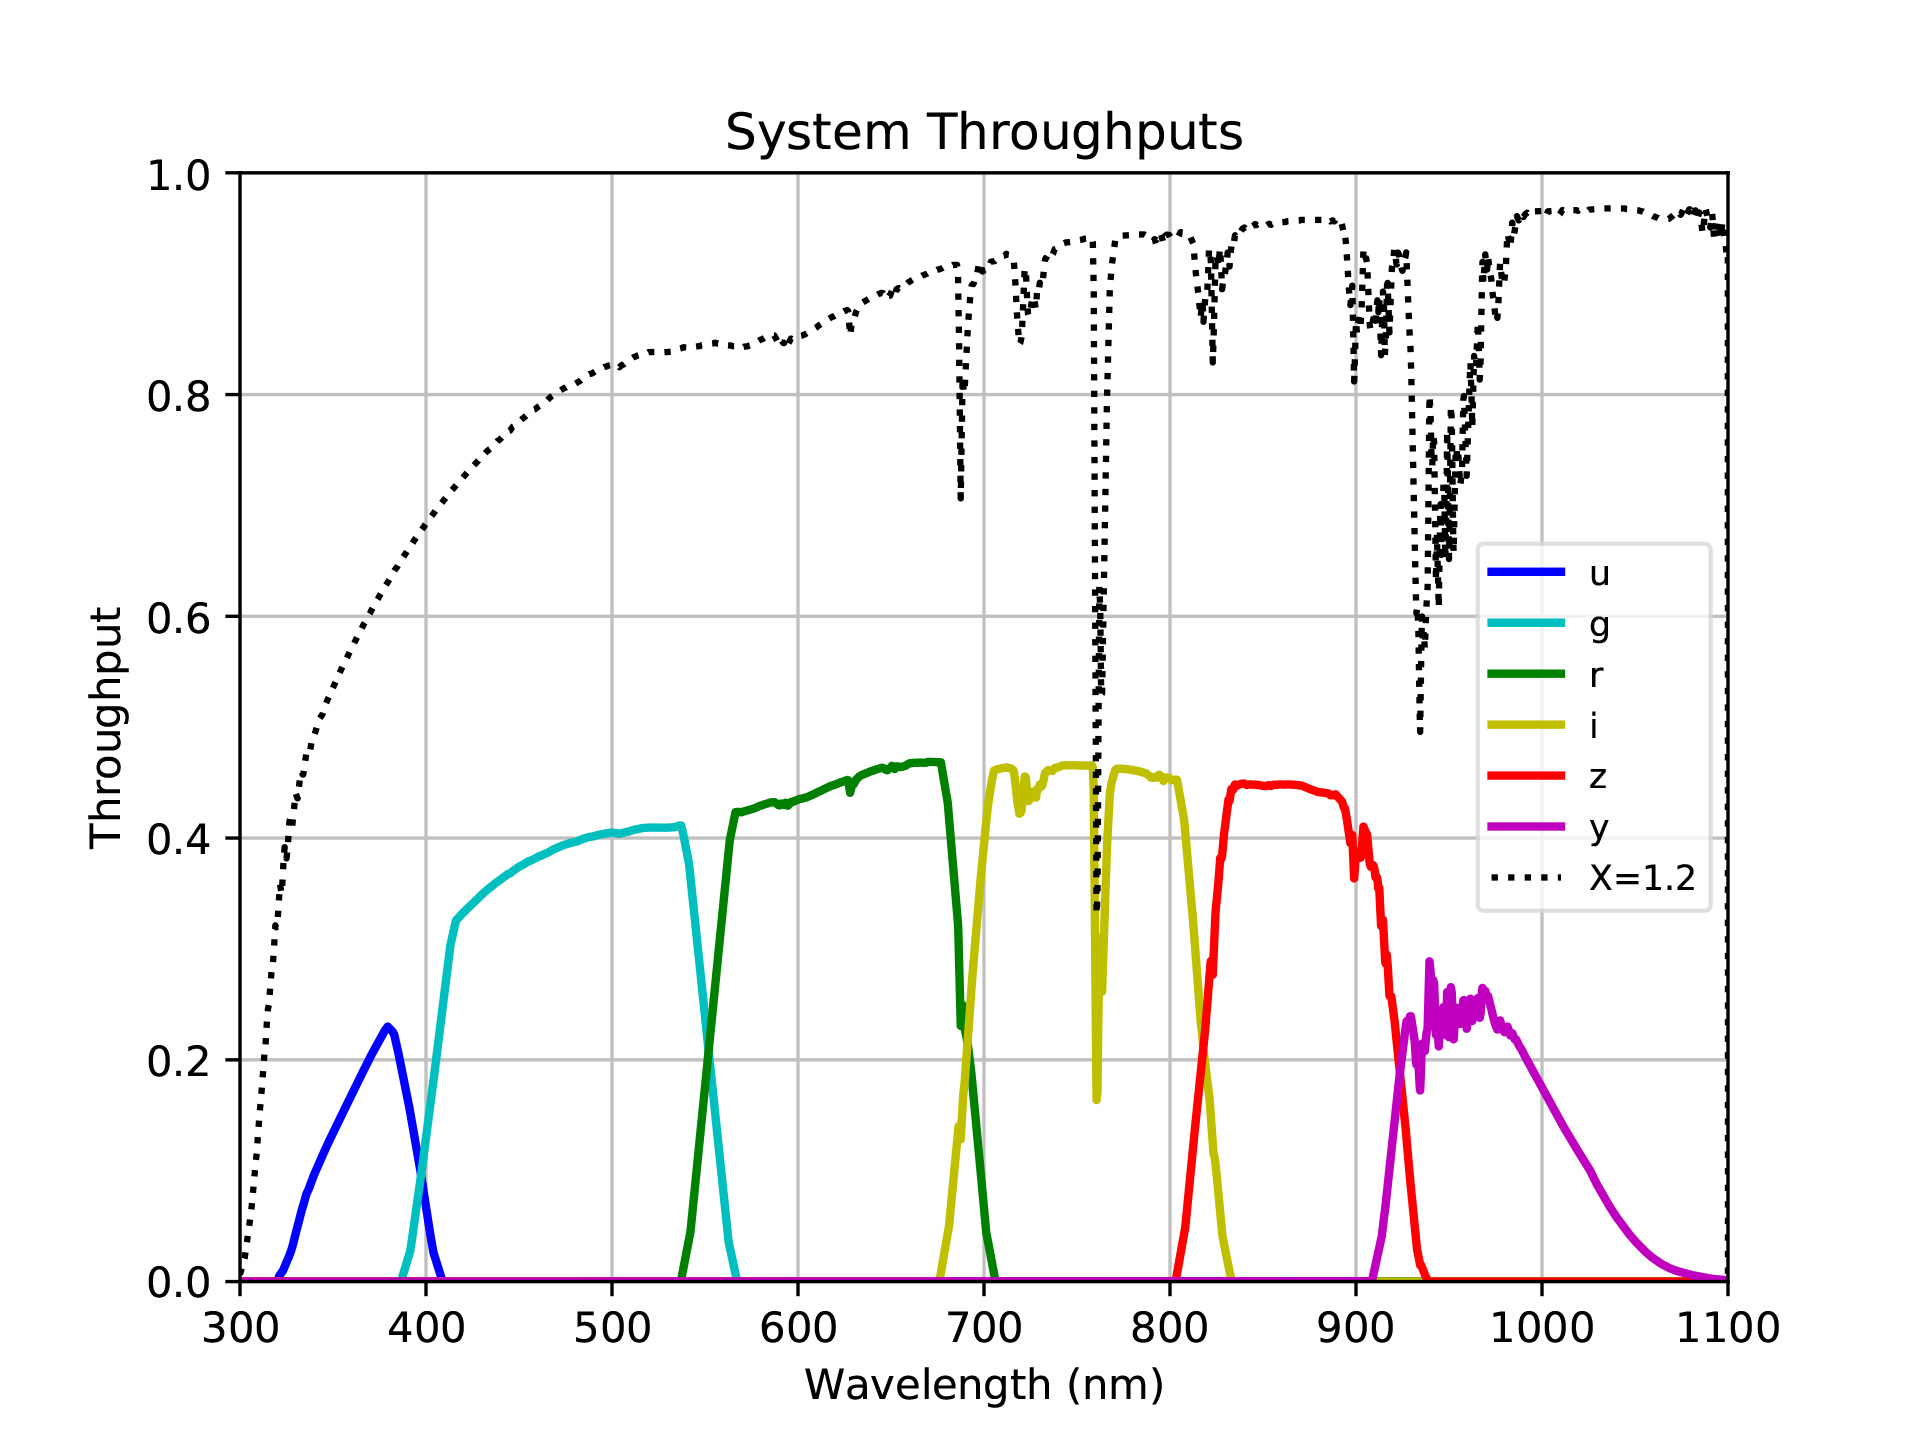

### Read and filter asteroids

Columns of the file:

In [3]:
data_file = data_dir + 'obs_sbn_X05_full.parquet'
columns = pq.read_schema(data_file).names
print_list(columns)

id, trksub, trkid, obsid, submission_id, submission_block_id, obs80, status,
ref, healpix, permid, provid, artsat, mode, stn, trx, rcv, sys, ctr, pos1, pos2,
pos3, poscov11, poscov12, poscov13, poscov22, poscov23, poscov33, prog, obstime,
ra, dec, rastar, decstar, obscenter, deltara, deltadec, dist, pa, rmsra, rmsdec,
rmsdist, rmspa, rmscorr, delay, rmsdelay, doppler, rmsdoppler, astcat, mag,
rmsmag, band, photcat, photap, nucmag, logsnr, seeing, exp, rmsfit, com, frq,
disc, subfrm, subfmt, prectime, precra, precdec, unctime, notes, remarks,
deprecated, localuse, nstars, prev_desig, prev_ref, rmstime, created_at,
updated_at, trkmpc, orbit_id, designation_asterisk, shapeocc, obssubid,
replacesobsid, group_id, vel1, fltr, vel3, vel2, obstime_text


### Read all asteroids with rotations

In [61]:
df_rot = pd.read_csv(data_dir + 'asteroids-with-rotation.csv')
df_rot.head()

,designation,provid,alt_designation,notes,superfast_rotator,H_mag,mean_mag_r,n_obs,arc_days,period_lsm_hr,...,g_minus_r_lsm,g_minus_r_fourier,g_minus_r_str,g_minus_i_lsm,g_minus_i_fourier,g_minus_i_str,r_minus_i_lsm,r_minus_i_fourier,r_minus_i_str,axial_elongation
0,2025 MA19,2025 MA19,NaN,NaN,False,18.1,22.66,447,9,8.9,...,0.44,0.46,0.44 / 0.46,0.49,0.55,0.49 / 0.55,0.05,0.08,0.05 / 0.08,2.1
1,2025 MA45,2025 MA45,2015 KR298,"a,b",True,19.5,22.50,140,12,1.6,...,0.35,0.45,0.35 / 0.45,0.65,0.60,0.65 / 0.60,0.30,0.14,0.30 / 0.14,1.5
2,2025 MA46,2025 MA46,NaN,NaN,False,18.1,23.13,291,12,5.9,...,0.53,0.53,0.53 / 0.53,0.71,0.68,0.71 / 0.68,0.18,0.15,0.18 / 0.15,1.6
3,2025 MC34,2025 MC34,NaN,NaN,False,18.5,23.02,321,12,8.4,...,0.52,0.49,0.52 / 0.49,0.69,0.70,0.69 / 0.70,0.16,0.21,0.16 / 0.21,1.9
4,2025 MD38,2025 MD38,2014 HR48,a,False,18.0,22.80,458,12,15.8,...,0.46,0.46,0.46 / 0.46,0.54,0.59,0.54 / 0.59,0.08,0.13,0.08 / 0.13,2.2


In [62]:
print_list(df_rot.columns)

designation, provid, alt_designation, notes, superfast_rotator, H_mag,
mean_mag_r, n_obs, arc_days, period_lsm_hr, period_fourier_hr, period_str,
amplitude_lsm, amplitude_fourier, amplitude_str, g_minus_r_lsm,
g_minus_r_fourier, g_minus_r_str, g_minus_i_lsm, g_minus_i_fourier,
g_minus_i_str, r_minus_i_lsm, r_minus_i_fourier, r_minus_i_str, axial_elongation


### Filter data

Read all data:

In [4]:
columns = [
    'obstime', 'permid', 'provid',
    'ra', 'dec', 'band', 'mag', 'rmsmag'
]

df_full = pd.read_parquet(
    data_file,
    columns=columns,
)
print(f"Original number of observations: {len(df_full)}")

Original number of observations: 8078546


We will filter data having `provid` or `permid`:

In [5]:
df_set = df_full[~(df_full['provid'].isna() & df_full['permid'].isna())].reset_index(drop=True)
print(f"Number of observations with provid or permid: {len(df_set)}")

Number of observations with provid or permid: 8014721


Now I want only those with asteroidal `provid`, ie. obeying the pattern `CCYY LL[NN]` (eg. 2025 MN45):

In [6]:
asteroid_provid_pattern = re.compile(r'^\d{4} [A-Z]{2}\d+[A-Z]?$')
df_set = df_set[df_set['provid'].apply(lambda pid: bool(asteroid_provid_pattern.match(str(pid))))].reset_index(drop=True)
print(f"Number of observations with asteroid provid: {len(df_set)}")

provids = df_set['provid'].dropna().unique()
permids = df_set['permid'].dropna().unique()
bothids = df_set.dropna(subset=['permid','provid'])['provid'].unique()
print(f"Number of objects with provid:  {len(provids)}")
print(f"Number of objects with permid: {len(permids)}")
print(f"Number of objects with both ids: {len(bothids)}")
df_set.head()

Number of observations with asteroid provid: 7870711
Number of objects with provid:  297318
Number of objects with permid: 176882
Number of objects with both ids: 176903


,obstime,permid,provid,ra,dec,band,mag,rmsmag
0,2025-05-02 00:42:01.796,NaN,2025 MD8,186.158016,4.012876,i,23.096,0.124
1,2025-05-02 00:39:54.996,NaN,2025 MD8,186.158229,4.012886,i,22.927,0.127
2,2025-05-02 01:01:01.387,NaN,2025 MD8,186.156548,4.013182,i,23.055,0.105
3,2025-05-02 01:03:10.218,NaN,2025 MD8,186.156327,4.01323,i,23.059,0.129
4,2025-05-02 01:29:18.645,NaN,2025 MD8,186.154292,4.01363,r,22.911,0.072


Change label for filers

In [7]:
# Cambia (por ejemplo) 'r' -> 'Lr', 'g' -> 'Lg', etc. en df_set['band']:
# Remove columns that are single-letter LSST bands ('r', 'g', 'i', 'z', 'y', 'u')
df_set['band'] = df_set['band'].apply(lambda b: f"L{b}" if pd.notnull(b) and len(str(b)) == 1 else b)
band_columns_to_remove = ['r', 'g', 'i', 'z', 'y', 'u']
df_set = df_set.drop(columns=[col for col in band_columns_to_remove if col in df_set.columns])

Sort observations by date and convert data:

In [8]:
# Sort observations
df_set = df_set.sort_values(
    by=['provid', 'band', 'obstime'],
    ascending=[True, True, True]
).reset_index(drop=True)

# Convert data
cols = ['ra', 'dec', 'mag', 'rmsmag']
df_set[cols] = df_set[cols].apply(pd.to_numeric, errors='coerce')
df_set['night'] = df_set['obstime'].dt.floor('D')

Clean memory and compute RAM memory usage:

In [9]:
del(df_full)
total_sizeof_globals()

Total RAM used by notebook variables: 654.42 MB


Cross match orbital data:

In [10]:
df_elems = extract_orbital_elements_from_mpcorb(provids)
df_elems

,provid,number,name,H,G,epoch,epoch_jd,M,argperi,node,i,e,n,a,nobs,nopp,arc,rms
0,1931 TB2,2855,Bastian,13.29,0.15,K2669,2.460524e+06,173.63728,100.33561,338.96726,8.14295,0.169013,0.25648098,2.453386,4031,26,1931-2026,0.73
1,1931 TF2,1232,Cortusa,10.30,0.15,K2669,2.461135e+06,11.47022,340.66262,260.69982,10.37600,0.142260,0.17421345,3.175033,6661,45,1930-2026,0.65
2,1931 TJ1,3379,Oishi,13.37,0.15,K2669,2.461174e+06,7.23223,304.44094,146.71841,2.85411,0.130547,0.27268981,2.355176,5033,30,1931-2026,0.74
3,1931 TN1,1941,Wild,11.83,0.15,K2669,2.461451e+06,328.62697,303.07122,60.39420,3.95630,0.288755,0.12517551,3.957824,3890,36,1915-2026,0.75
4,1931 TS1,5072,Hioki,12.92,0.15,K2669,2.461057e+06,28.42841,2.06104,10.83959,2.01352,0.082769,0.19861493,2.909342,5486,31,1931-2026,0.66
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
294974,2026 KB6,<NA>,,7.07,0.15,K2669,2.452690e+06,19.92996,116.40284,72.05461,31.97982,0.351578,0.00234173,56.162249,13,1,48 days,0.09
294975,2026 KO6,<NA>,,7.26,0.15,K2669,2.449798e+06,46.02190,37.36887,138.84223,8.41402,0.132952,0.00403637,39.066869,12,1,48 days,0.07
294976,2026 OL3,<NA>,,23.19,0.15,K2669,2.461300e+06,321.27148,83.62188,301.54246,2.89417,0.598438,0.38955004,1.856780,22,1,12 days,0.45
294977,2026 RL12,<NA>,,18.02,0.15,K2669,2.461018e+06,32.95341,312.72441,334.80783,13.34427,0.138322,0.18028558,3.103336,65,6,2004-2026,0.37


In [11]:
total_sizeof_globals()

Total RAM used by notebook variables: 706.35 MB


### Asteroid Lightcurve

Select asteroid:

- By name:

In [55]:
# name = "Apophis"
name = "Jorgezuluaga"
obj = SBDB.query(name)
permid = obj["object"]["des"]  
try:
    provid = df_set[df_set['permid'] == permid]['provid'].unique()[0]
    name = df_elems[df_elems['number'] == float(permid)]['name'].unique()[0]
except:
    provid = 'Unknown'
    name = 'Unknown'
print(f"Asteroid: {permid} {name} ({provid})")

Asteroid: 347940 Jorgezuluaga (2003 FZ128)


- By permid:

In [56]:
permid = '347940'
provid = df_set[df_set['permid'] == permid]['provid'].unique()[0]
try:
    name = df_elems[df_elems['number'] == float(permid)]['name'].unique()[0]
except:
    name = 'Unknown'
print(f"Asteroid: {permid} {name} ({provid})")

Asteroid: 347940 Jorgezuluaga (2003 FZ128)


- By provid:

In [93]:
provid = '2025 MM82'
#provid = '2025 MT24'

Obtain all available physical properties from JPL including rotational period, sizes, etc.

In [43]:
# Physical properties from JPL SBDB (only those that are available).
target = provid or permid
sbdb = SBDB.query(str(target), phys=True)
phys = sbdb.get('phys_par') or {}
obj = sbdb.get('object') or {}
print(obj.get('fullname') or obj.get('des') or target)

rows = []
for key, value in phys.items():
    if key.endswith(('_sig', '_ref', '_note')) or value in (None, ''):
        continue
    rows.append({
        'parameter': key,
        'value': value,
        'sigma': phys.get(f'{key}_sig'),
        'reference': phys.get(f'{key}_ref'),
        'note': phys.get(f'{key}_note'),
    })

df_phys = pd.DataFrame(rows)
if df_phys.empty:
    print(f'No physical properties in SBDB for {target}.')
else:
    print(df_phys.to_string(index=False))


347940 Jorgezuluaga (2003 FZ128)
parameter  value sigma reference note
        H  16.09  None MPO984244 None


Get all observations:

In [14]:
df_obj = df_set[(df_set['provid'] == provid)].copy()
print(f"Number of observations: {len(df_obj)}")

t0 = df_obj['obstime'].iloc[0]
df_obj['t_days'] = (df_obj['obstime'] - t0).dt.total_seconds() / 86400.0

print(f"Total observations of Asteroid {provid}: {len(df_obj)}")
print(f"Observing arc: {(df_obj['obstime'].max() - t0).total_seconds() / 86400.0:.2f} days")
print(f"Observations per band: {df_obj['band'].value_counts().to_dict()}")

Number of observations: 464
Total observations of Asteroid 2025 MM82: 464
Observing arc: 9.02 days
Observations per band: {'Lr': 203, 'Li': 134, 'Lg': 127}


### Compute absolute magnitudes

In [15]:
object_names = df_obj['provid']
obs_times = df_obj['obstime']
mags = df_obj['mag']
bands = df_obj['band']
N = len(mags)
print(f"Number of observations: {N}")

Number of observations: 464


In [16]:
# do the query and generate the master catalog
name_arr = np.asarray(object_names)
time_arr = np.asarray(obs_times)

dist_ = np.empty(N)
alpha_ = np.empty(N)
r_ = np.empty(N)
a_ = np.empty(N)
e_ = np.empty(N)
i_ = np.empty(N)
omega_ = np.empty(N)
Omega_ = np.empty(N)
M_ = np.empty(N)

for name in pd.unique(name_arr):
    sel = np.flatnonzero(name_arr == name)
    dist, alpha, r, a, e, inc, omega, Omega, M = query_dists_and_elements(name, time_arr[sel])
    dist_[sel] = dist
    alpha_[sel] = alpha
    r_[sel] = r
    a_[sel] = a
    e_[sel] = e
    i_[sel] = inc
    omega_[sel] = omega
    Omega_[sel] = Omega
    M_[sel] = M

props = pd.DataFrame({
    'object_names': object_names,
    'obs_times': obs_times,
    'mag': mags,
    'band': bands,
    'dist': dist_,
    'alpha': alpha_,
    'r': r_,
    'a': a_,
    'e': e_,
    'i': i_,
    'omega': omega_,
    'Omega': Omega_,
    'M': M_
})

# calculate H
props['H'] = props.apply(
    lambda row: mag_abs(
        mag=row['mag'],
        alpha=row['alpha'],
        dist=row['dist'],
        r=row['r']
    ),
    axis=1
)

df_obj[['dist', 'alpha', 'r', 'H']] = props[['dist', 'alpha', 'r', 'H']]

Horizons batch 1/10: 50 epochs of 2025 MM82
Horizons batch 2/10: 50 epochs of 2025 MM82
Horizons batch 3/10: 50 epochs of 2025 MM82
Horizons batch 4/10: 50 epochs of 2025 MM82
Horizons batch 5/10: 50 epochs of 2025 MM82
Horizons batch 6/10: 50 epochs of 2025 MM82
Horizons batch 7/10: 50 epochs of 2025 MM82
Horizons batch 8/10: 50 epochs of 2025 MM82
Horizons batch 9/10: 50 epochs of 2025 MM82
Horizons batch 10/10: 14 epochs of 2025 MM82


### Plot observations

Plot all observations:

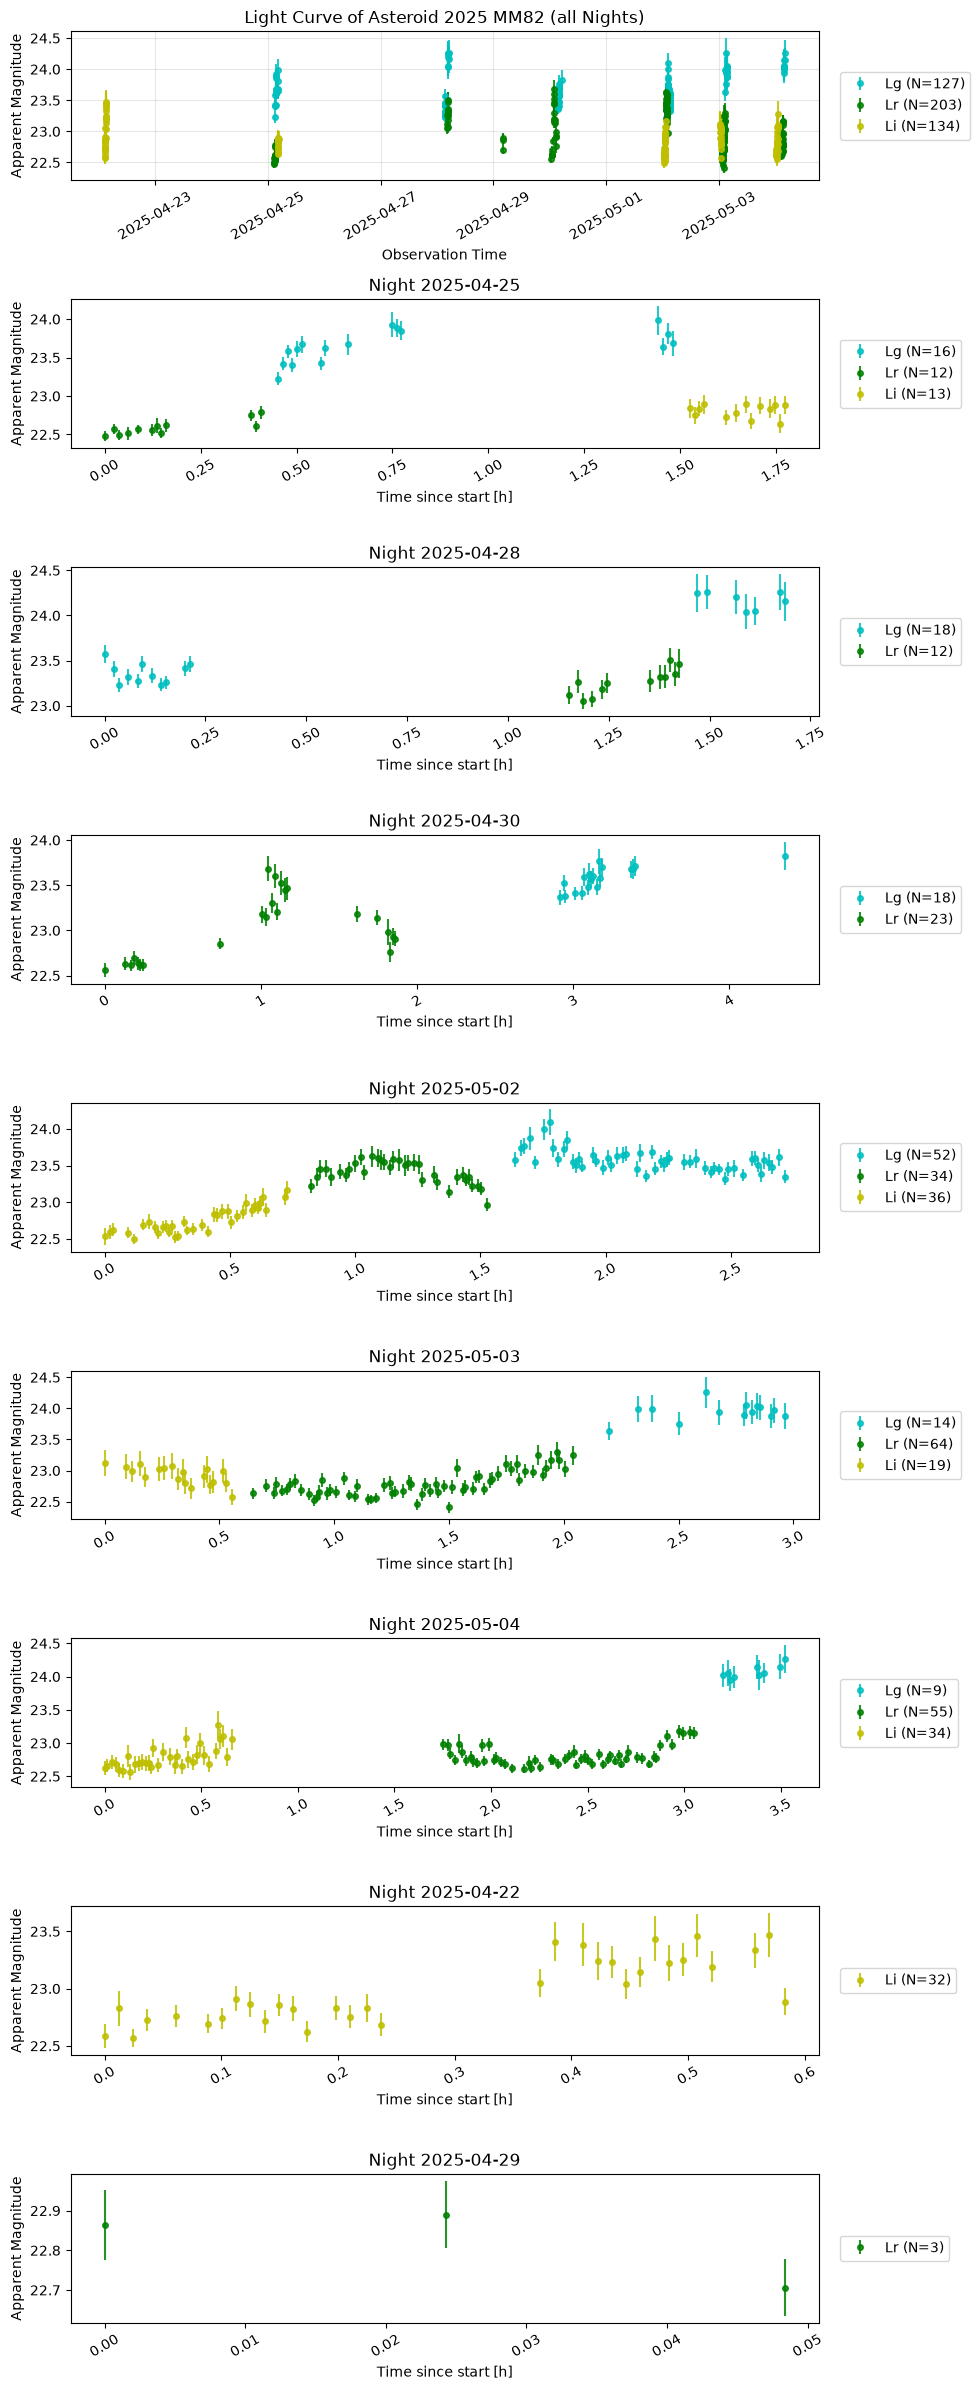

In [23]:
verbose = 0
nights = df_obj.night.unique()
n_nights = len(nights)

fig, axs = plt.subplots(n_nights + 1, 1, figsize=(10, 3*n_nights))

# All data
ax = axs[0]
df_obj = df_obj.copy()
for b in BANDS:
    sb = df_obj[df_obj['band'] == b]
    if len(sb) > 0:
        ax.errorbar(sb['obstime'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax.set_xlabel(f"Observation Time")
ax.set_ylabel('Apparent Magnitude')
ax.tick_params(axis='x', rotation=30)
ax.set_title(f"Light Curve of Asteroid {provid} (all Nights)")
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
ax.grid(True, alpha=0.3)

for i, night in enumerate(nights):
    night_str = pd.to_datetime(night).strftime('%Y-%m-%d')
    if verbose:print(f"Processing night {night_str}")
    ax = axs[i+1]
    t_night = df_obj[df_obj['night'] == night].copy()
    t_night_0 = min(t_night['obstime'])
    t_night['h'] = (t_night['obstime'] - t_night_0).dt.total_seconds() / 3600.0
    for b in ALL_BANDS:
        sb = t_night[t_night['band'] == b]
        if len(sb) > 0:
            if verbose:print(f"\tBand {b}: {len(sb)} observations")
            ax.errorbar(sb['h'], sb['mag'], yerr=sb['rmsmag'], fmt='o', 
                        label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)
    
    ax.set_title(f"Night {night_str}")
    ax.set_xlabel(f"Time since start [h]")
    ax.set_ylabel('Apparent Magnitude')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
    ax.tick_params(axis='x', rotation=30)

fig.tight_layout()
fig.savefig(fig_dir + f"lightcurve_allnights_{provid.replace(' ', '_')}.png", dpi=300)

### Absolute magnitudes

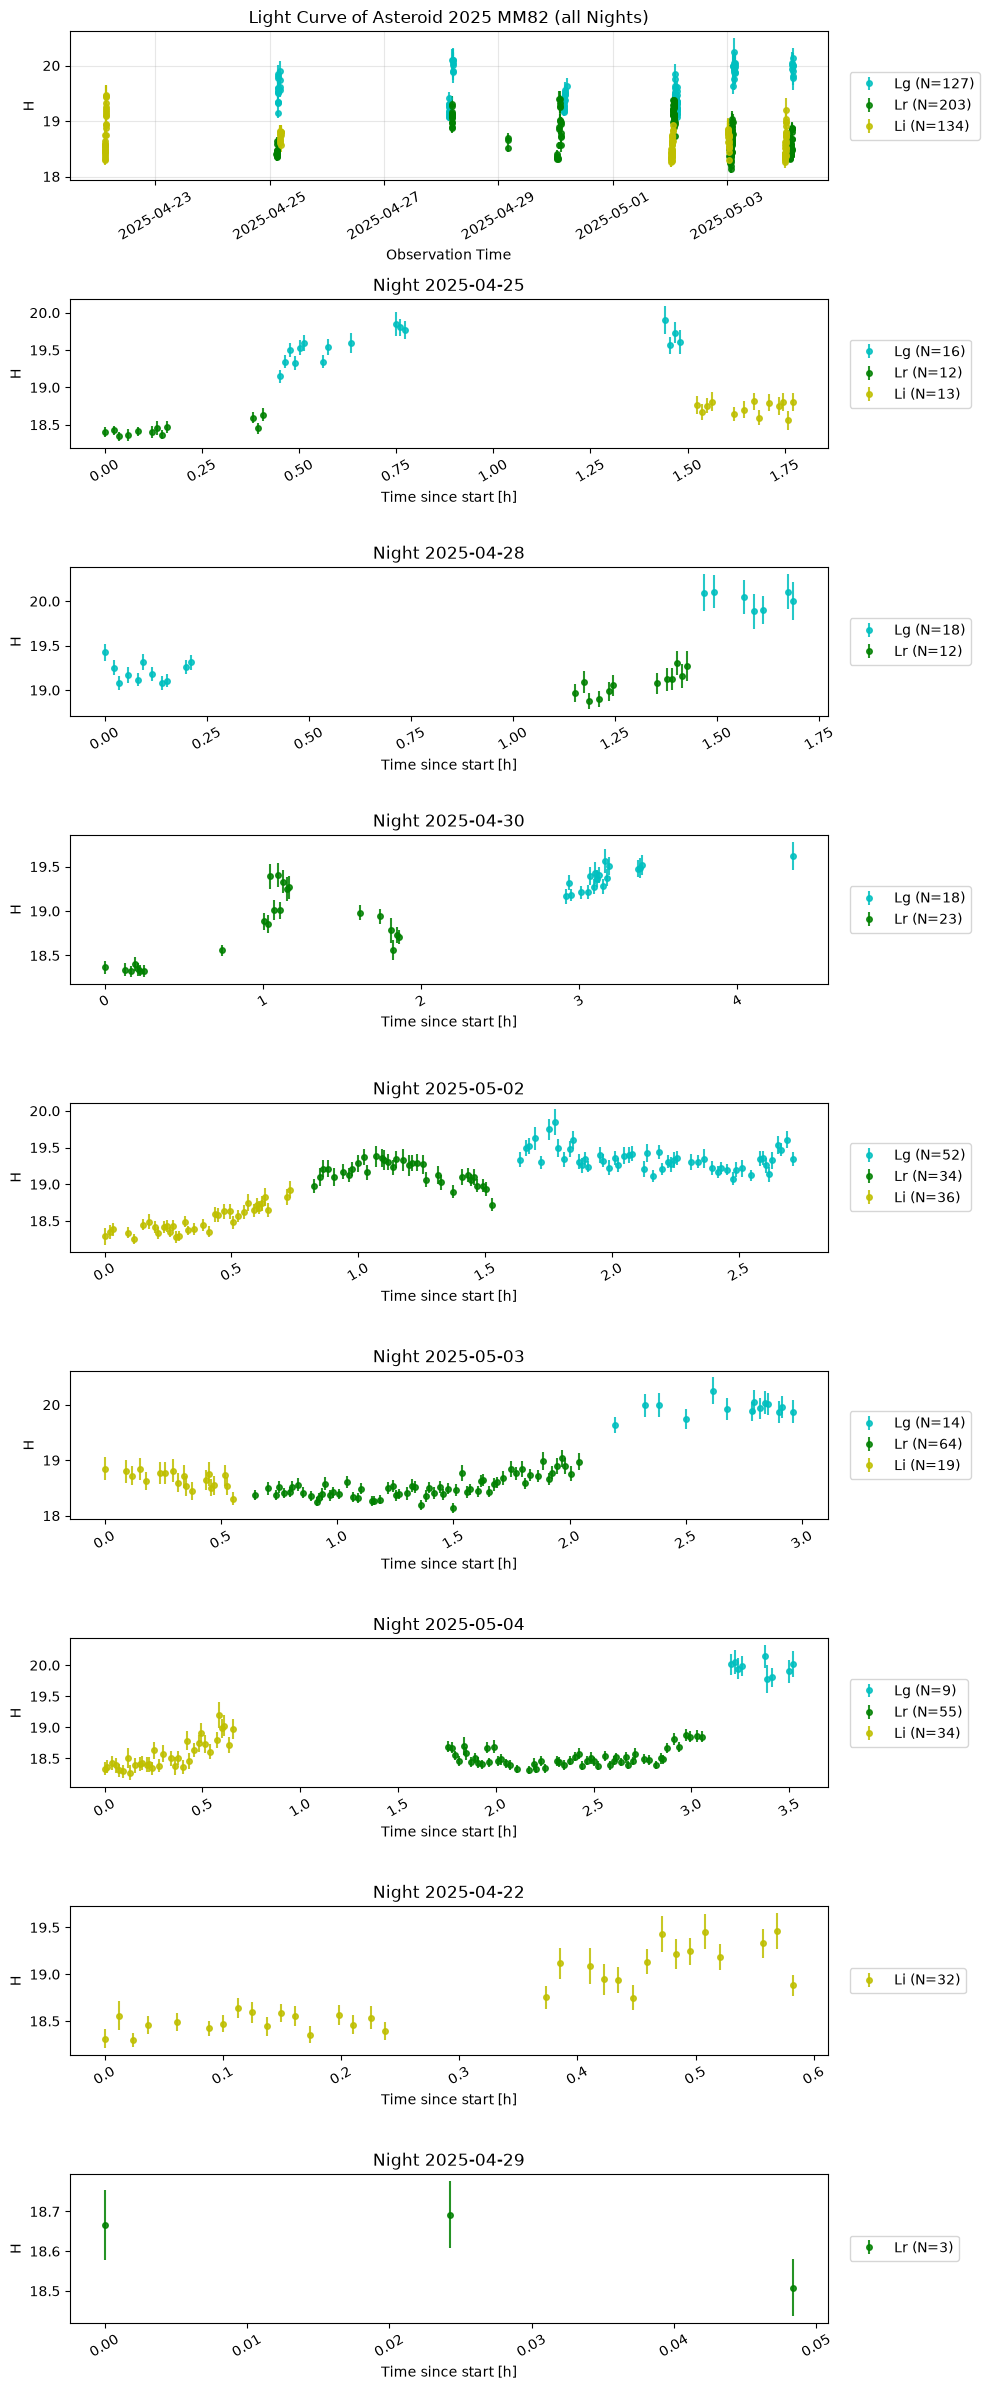

In [25]:
verbose = 0
nights = df_obj.night.unique()
n_nights = len(nights)

fig, axs = plt.subplots(n_nights + 1, 1, figsize=(10, 3*n_nights))

# All data
ax = axs[0]
df_obj = df_obj.copy()
for b in BANDS:
    sb = df_obj[df_obj['band'] == b]
    if len(sb) > 0:
        ax.errorbar(sb['obstime'], sb['H'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax.set_xlabel(f"Observation Time")
ax.set_ylabel('H')
ax.tick_params(axis='x', rotation=30)
ax.set_title(f"Light Curve of Asteroid {provid} (all Nights)")
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
ax.grid(True, alpha=0.3)

for i, night in enumerate(nights):
    night_str = pd.to_datetime(night).strftime('%Y-%m-%d')
    if verbose:print(f"Processing night {night_str}")
    ax = axs[i+1]
    t_night = df_obj[df_obj['night'] == night].copy()
    t_night_0 = min(t_night['obstime'])
    t_night['h'] = (t_night['obstime'] - t_night_0).dt.total_seconds() / 3600.0
    for b in ALL_BANDS:
        sb = t_night[t_night['band'] == b]
        if len(sb) > 0:
            if verbose:print(f"\tBand {b}: {len(sb)} observations")
            ax.errorbar(sb['h'], sb['H'], yerr=sb['rmsmag'], fmt='o', 
                        label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)
    
    ax.set_title(f"Night {night_str}")
    ax.set_xlabel(f"Time since start [h]")
    ax.set_ylabel('H')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
    ax.tick_params(axis='x', rotation=30)

fig.tight_layout()
fig.savefig(fig_dir + f"lightcurve_allnights_{provid.replace(' ', '_')}.png", dpi=300)

### Distance-phase modulus

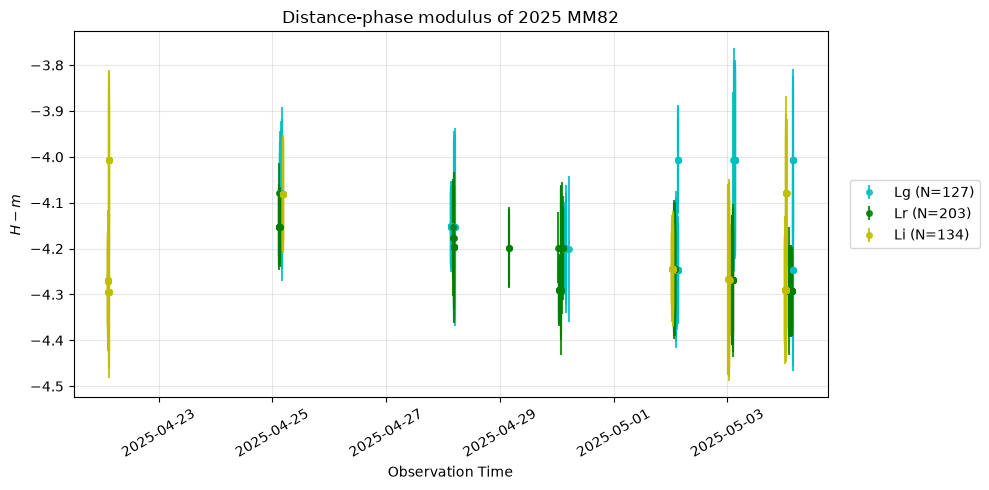

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))

for b in ALL_BANDS:
    sb = df_obj[df_obj['band'] == b]
    if len(sb) == 0:
        continue
    ax.errorbar(sb['obstime'], sb['H'] - sb['mag'], yerr=sb['rmsmag'], fmt='o',
                label=f'{b} (N={len(sb)})', color=BAND_COLORS.get(b, 'k'),
                markersize=4, alpha=0.85)

ax.set_xlabel('Observation Time')
ax.set_ylabel(r'$H - m$')
ax.set_title(f'Distance-phase modulus of {provid}')
ax.tick_params(axis='x', rotation=30)
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(fig_dir + f"distance_modulus_{provid.replace(' ', '_')}.png", dpi=300)


### Periodogram

Now we get the rotation period from a Lomb-Scargle periodogram.

We can choose which band:

In [27]:
print(f"Observations per band: {df_obj['band'].value_counts().to_dict()}")

Observations per band: {'Lr': 203, 'Li': 134, 'Lg': 127}


Photometric period: 2.51 hours
Derived asteroid rotation period: 5.02 hours

All periodogram peaks with >80% of main peak power:
[0] Rotational Period = 10.28 h | Power = 0.804
[1] Rotational Period = 6.36 h | Power = 0.801
[2] Rotational Period = 5.61 h | Power = 0.953
[3] Rotational Period = 5.02 h | Power = 1.000
[4] Rotational Period = 4.54 h | Power = 0.957
[5] Rotational Period = 4.15 h | Power = 0.835


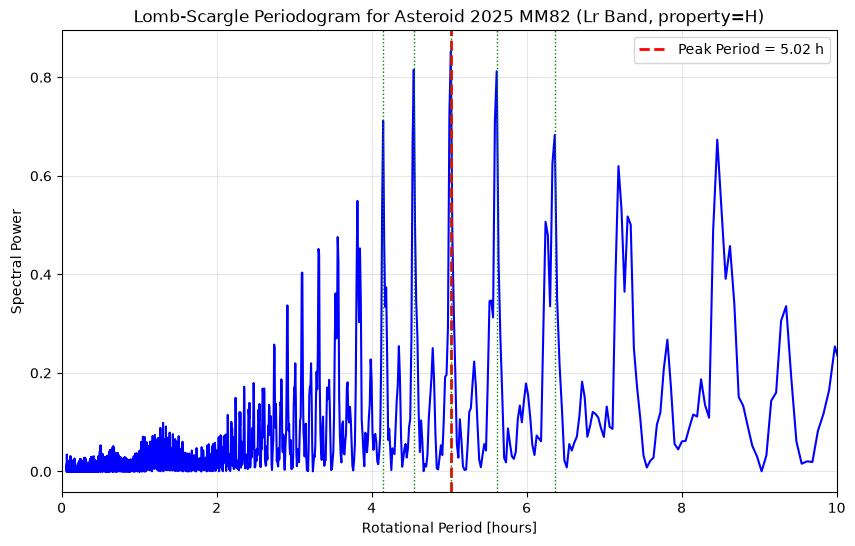

In [30]:
band = 'Lr'
prop = 'H'

df_band = df_obj[df_obj['band'] == band].copy()
t_band = df_band['t_days'].values
y_band = df_band[prop].values
dy_band = df_band['rmsmag'].fillna(0.01).values

# Frequency grid: 1.0 to 10.0 cycles/day (corresponding to periods from 2.4 to 24 hours)
periods = [2/60, 24] # in hours
freq_grid = np.linspace(24/periods[1], 24/periods[0], 20000)
ls_band = LombScargle(t_band, y_band, dy_band)
power = ls_band.power(freq_grid)

main_peak_power = np.max(power)
best_freq = freq_grid[np.argmax(power)]
best_phot_period = 24.0 / best_freq
best_rot_period = 2.0 * best_phot_period  # Double-peaked rotational period
print(f"Photometric period: {best_phot_period:.2f} hours")
print(f"Derived asteroid rotation period: {best_rot_period:.2f} hours")

# Find periodogram peaks
peaks, _ = find_peaks(power)
threshold = 0.8 * main_peak_power
high_power_indices = np.where(power >= threshold)[0]
high_power_peaks = np.intersect1d(peaks, high_power_indices)

print(f"\nAll periodogram peaks with >80% of main peak power:")

all_rot_periods = []
peak_data = []
for i, idx in enumerate(high_power_peaks):
    freq = freq_grid[idx]
    ph_per = 24.0 / freq
    rot_per = 2.0 * ph_per
    rel_pwr = power[idx] / main_peak_power
    all_rot_periods = np.append(all_rot_periods, rot_per)
    peak_data.append({
        "frequency": freq,
        "rotational_period_h": rot_per,
        "relative_power": rel_pwr
    })
    print(f"[{i}] Rotational Period = {rot_per:.2f} h | Power = {rel_pwr:.3f}")
df_peaks = pd.DataFrame(peak_data).sort_values(by='relative_power', ascending=False).reset_index(drop=True) 

fig, ax = plt.subplots(figsize=(10, 6))

period_grid_hours = (24.0 / freq_grid) * 2.0  # Converted to rotational period
ax.plot(period_grid_hours, power, color='b', lw=1.5)
ax.axvline(best_rot_period, color='r', linestyle='--', lw=2, label=f'Peak Period = {best_rot_period:.2f} h')
for period in all_rot_periods:
    ax.axvline(period, color='g', linestyle=':', alpha=1, lw=1)

ax.set_xlabel('Rotational Period [hours]')
ax.set_ylabel('Spectral Power')
ax.set_title(f'Lomb-Scargle Periodogram for Asteroid {provid} ({band} Band, property={prop})')
ax.set_xlim(0, 10)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, alpha=0.3)


Selected peak:

In [71]:
isel = 0
freq_sel = df_peaks.iloc[isel]['frequency']
per_sel = df_peaks.iloc[isel]['rotational_period_h']
rel_pwr = df_peaks.iloc[isel]['relative_power']
print(f"[{isel}] Rotational Period = {per_sel:.2f} h | Power = {rel_pwr:.3f}")


[0] Rotational Period = 5.02 h | Power = 1.000


Folded light-curve:

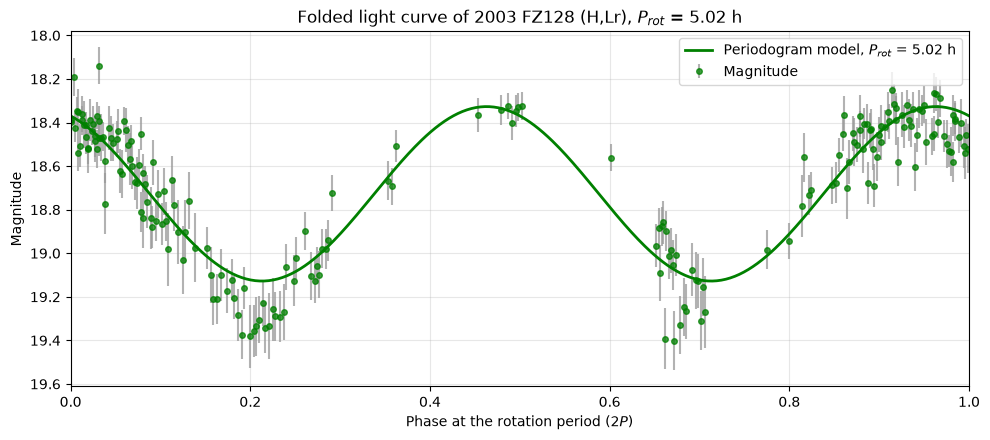

In [72]:
t0 = t_band.min()
phase = np.mod((t_band - t0) * freq_sel, 1.0)
phase_grid = np.linspace(0, 1, 400)
y_model = ls_band.model(t0 + phase_grid / freq_sel, freq_sel)

# Same model sampled across one rotation (two photometric cycles)
phase_rot = np.mod((t_band - t0) * freq_sel / 2.0, 1.0)
phase_rot_grid = np.linspace(0, 1, 400)
y_model_rot = ls_band.model(t0 + phase_rot_grid * 2.0 / freq_sel, freq_sel)

fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))

b = band if isinstance(band, str) else band[0]
curve_color = band_colors.get(b, 'k')
ax.errorbar(
    phase_rot, y_band, yerr=dy_band, fmt='o', ms=4, alpha=0.75,
    color=curve_color, ecolor='0.6', label='Magnitude'
)
ax.plot(
    phase_rot_grid, y_model_rot, color=curve_color, lw=2,
    label=f'Periodogram model, $P_{{rot}}$ = {best_rot_period:.2f} h'
)
ax.set_xlabel('Phase at the rotation period ($2P$)')
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', frameon=True)
ax.set_ylabel('Magnitude')
ax.set_title(f"Folded light curve of {provid} ({prop},{band}), $P_{{rot}}$ = {best_rot_period:.2f} h")
fig.tight_layout()
fig.savefig(fig_dir + f"phase_model_{provid.replace(' ', '_')}.png", dpi=300)

Now let's see the sine curve and the data:

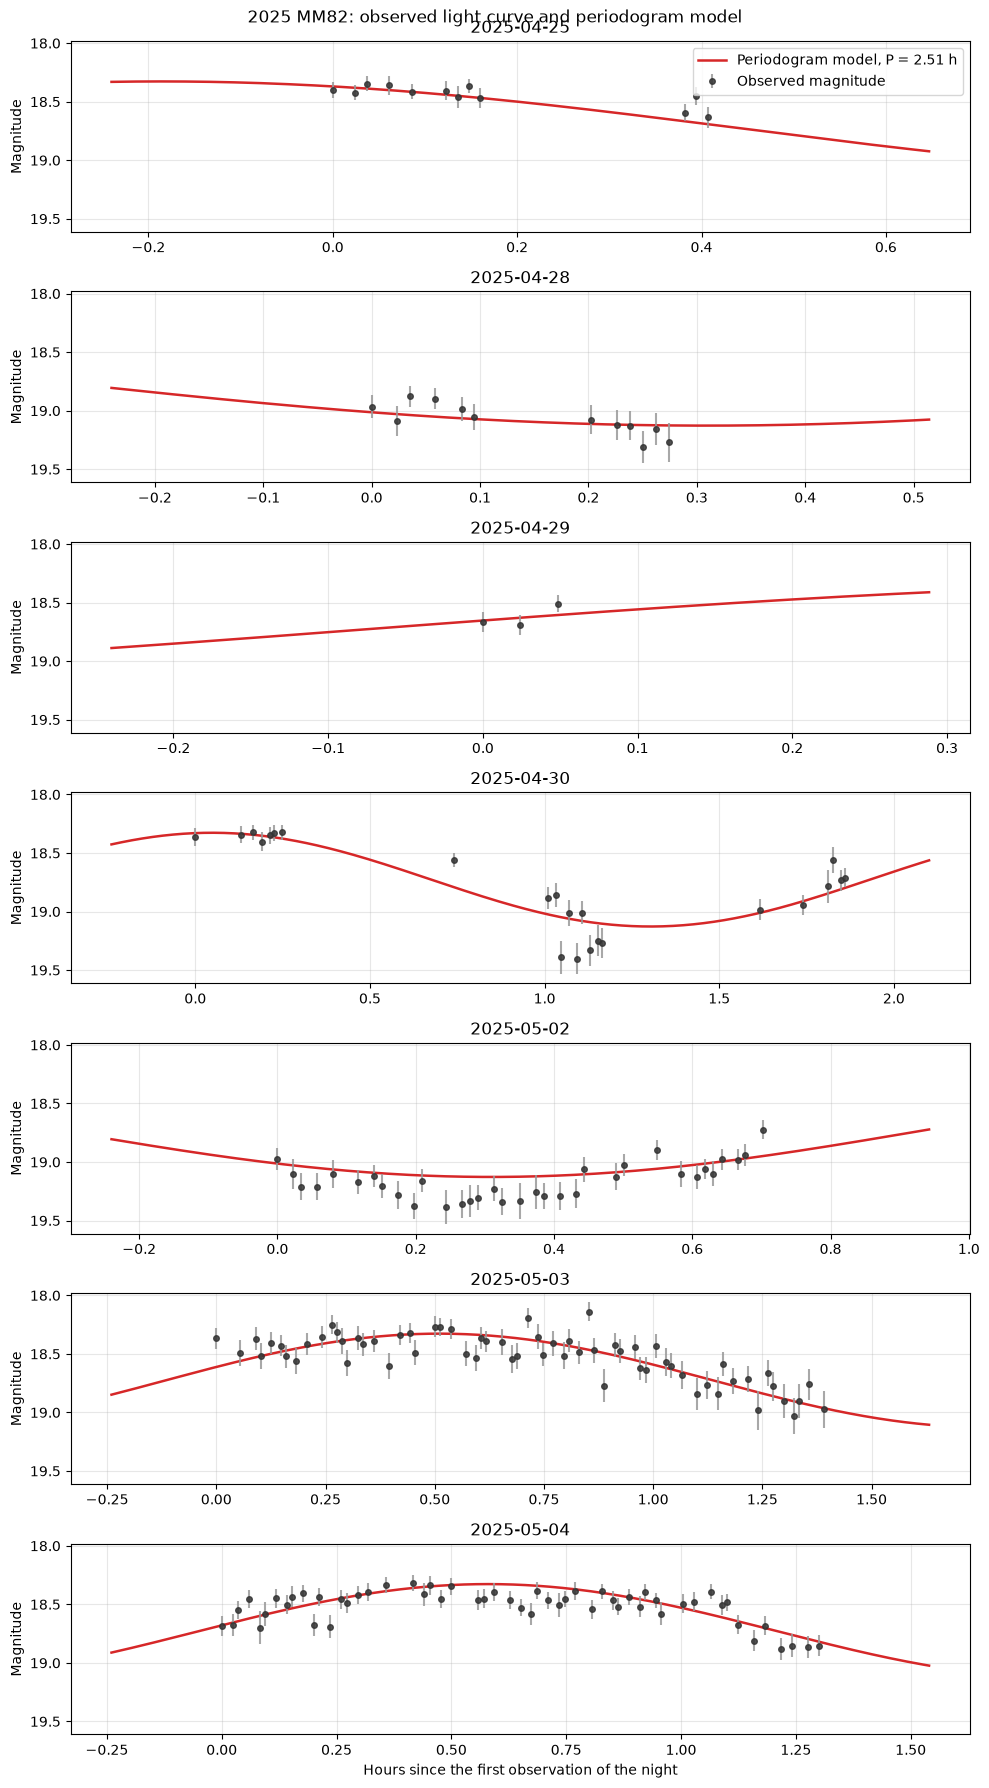

In [36]:
nights_band = df_band['night'].drop_duplicates().sort_values()
n_nights_band = len(nights_band)
fig, axs = plt.subplots(n_nights_band, 1, figsize=(10, 2.6 * n_nights_band), sharey=True)
if n_nights_band == 1:
    axs = [axs]

for ax, night in zip(axs, nights_band):
    sel = df_band['night'] == night
    t_night = df_band.loc[sel, 't_days'].to_numpy()
    y_night = df_band.loc[sel, prop].to_numpy()
    dy_night = df_band.loc[sel, 'rmsmag'].fillna(0.01).to_numpy()
    t_left, t_right = t_night.min(), t_night.max()
    pad = max(0.01, 0.05 * (t_right - t_left))
    t_grid = np.linspace(t_left - pad, t_right + pad, 400)
    y_grid = ls_band.model(t_grid, best_freq)
    hours = (t_night - t_left) * 24.0
    hours_grid = (t_grid - t_left) * 24.0
    ax.errorbar(
        hours, y_night, yerr=dy_night, fmt='o', ms=4, alpha=0.85,
        color='0.2', ecolor='0.6', label='Observed magnitude', zorder=3
    )
    ax.plot(
        hours_grid, y_grid, color='C3', lw=1.8,
        label=f'Periodogram model, P = {best_phot_period:.2f} h', zorder=2
    )
    ax.set_title(pd.to_datetime(night).strftime('%Y-%m-%d'))
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)

axs[0].invert_yaxis()
axs[0].legend(loc='best', frameon=True)
axs[-1].set_xlabel('Hours since the first observation of the night')
fig.suptitle(f'{provid}: observed light curve and periodogram model')
fig.tight_layout()
fig.savefig(fig_dir + f'timemodel_{provid.replace(" ", "_")}.png', dpi=300)


Brightest magnitude of each filter (m_max):
  Lg: 19.076
  Lr: 18.139
  Li: 18.254


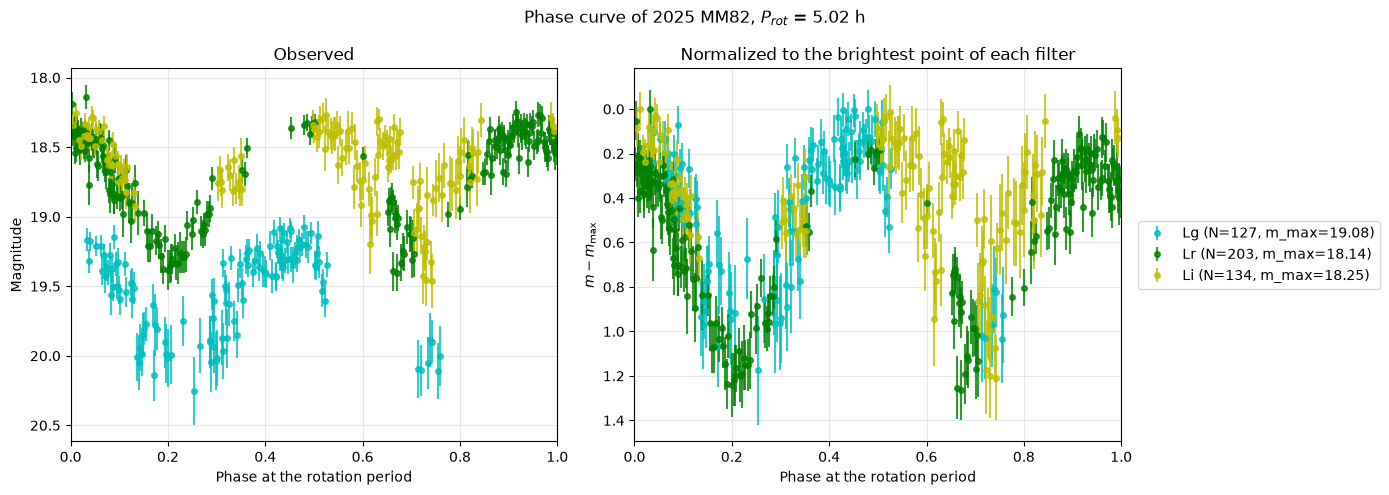

In [39]:
present = [b for b in ALL_BANDS if (df_obj['band'] == b).any()]
m_max = {}
for b in present:
    m_max[b] = df_obj[df_obj['band'] == b][prop].min()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
print('Brightest magnitude of each filter (m_max):')
for b, m in m_max.items():
    print(f'  {b}: {m:.3f}')

for b in present:
    sb = df_obj[df_obj['band'] == b]
    phase_b = np.mod((sb['t_days'].to_numpy() - t0) * freq_sel / 2.0, 1.0)
    dy = sb['rmsmag'].fillna(0.01)
    marker = 'o' if b.startswith('L') else 's'
    m = m_max[b]
    style = dict(fmt=marker, ms=4, alpha=0.8, color=band_colors.get(b, 'k'),
                 label=f'{b} (N={len(sb)}, m_max={m:.2f})')
    axes[0].errorbar(phase_b, sb[prop], yerr=dy, **style)
    axes[1].errorbar(phase_b, sb[prop] - m, yerr=dy, **style)

axes[0].set_ylabel('Magnitude')
axes[0].set_title('Observed')
axes[1].set_ylabel(r'$m - m_{\mathrm{max}}$')
axes[1].set_title('Normalized to the brightest point of each filter')
for ax in axes:
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('Phase at the rotation period')
    ax.grid(True, alpha=0.3)
axes[1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True)
fig.suptitle(f'Phase curve of {provid}, $P_{{rot}}$ = {per_sel:.2f} h')
fig.tight_layout()
fig.savefig(fig_dir + f'phase_allbands_{provid.replace(" ", "_")}.png', dpi=300)


### Compare with literature reported magnitudes

This code is to compare the folded curves with periods obtaind from the VRO photometry and from literature:

Literature reported periods: 5.00 h (LSM) / 5.00 h (Fourier)


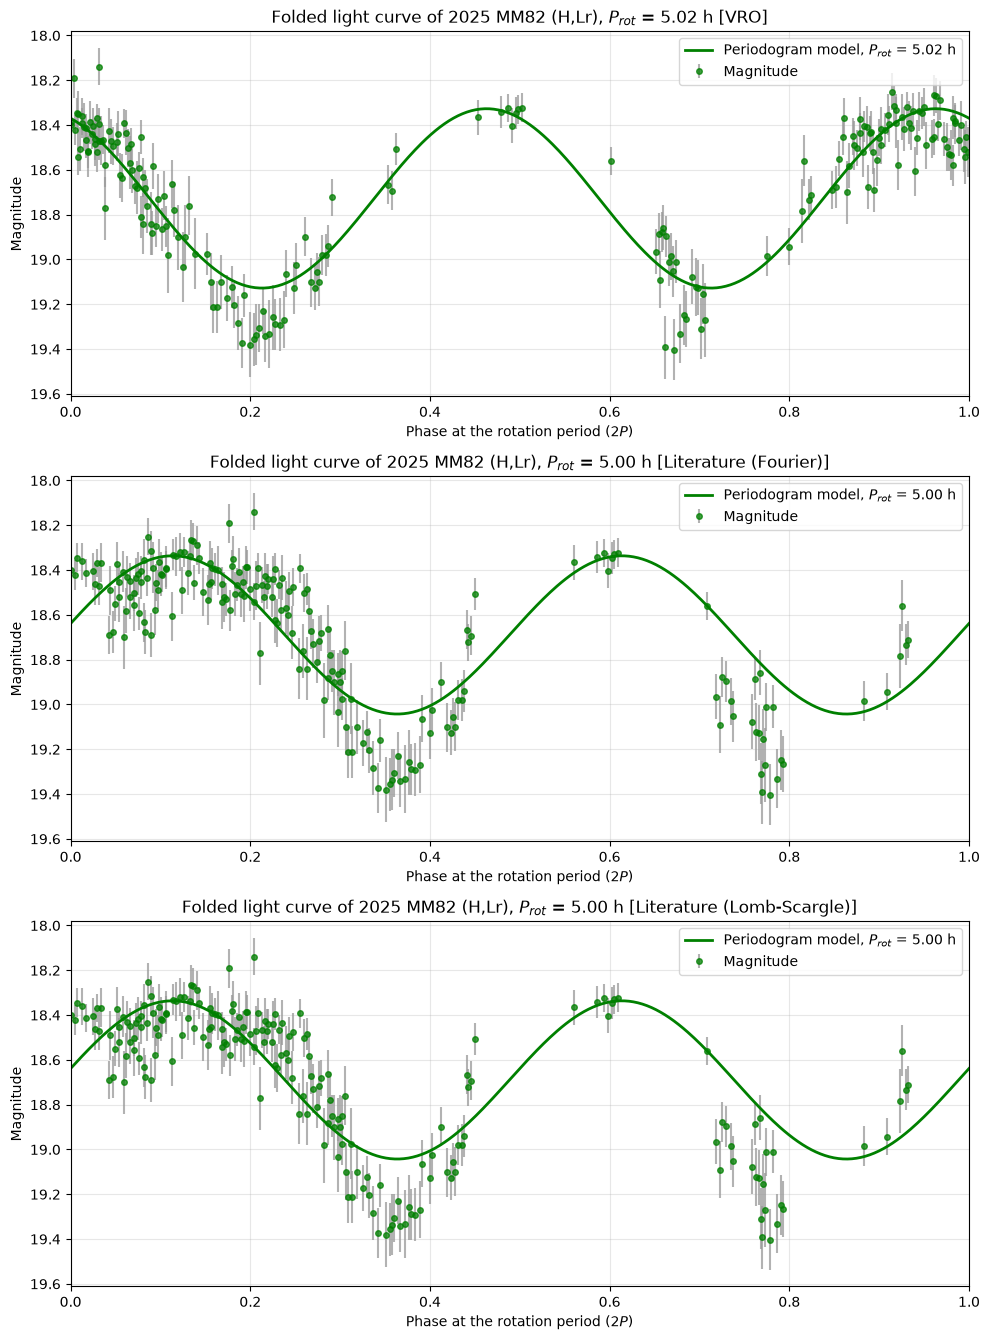

In [96]:
try:
    per_lit_ls = float(df_rot[df_rot['provid'] == provid].period_lsm_hr.iloc[0])
    per_lit_fr = float(df_rot[df_rot['provid'] == provid].period_fourier_hr.iloc[0])
    print(f"Literature reported periods: {per_lit_ls:.2f} h (LSM) / {per_lit_fr:.2f} h (Fourier)")
    periods = {
        'VRO': best_rot_period,
        'Literature (Fourier)': per_lit_fr,
        'Literature (Lomb-Scargle)': per_lit_ls,
    }
except:
    print(f"No literature reported periods for {provid}")
    periods = {
        'VRO': best_rot_period,
    }
    
fig, axs = plt.subplots(len(periods.keys()), 1, figsize=(10, 4.5*len(periods.keys())))
for i, item in enumerate(periods.items()):
    per = item[1]
    name = item[0]
    freq_sel = 24 / (per / 2)
    ax = axs[i]

    t0 = t_band.min()
    phase = np.mod((t_band - t0) * freq_sel, 1.0)
    phase_grid = np.linspace(0, 1, 400)
    y_model = ls_band.model(t0 + phase_grid / freq_sel, freq_sel)

    # Same model sampled across one rotation (two photometric cycles)
    phase_rot = np.mod((t_band - t0) * freq_sel / 2.0, 1.0)
    phase_rot_grid = np.linspace(0, 1, 400)
    y_model_rot = ls_band.model(t0 + phase_rot_grid * 2.0 / freq_sel, freq_sel)

    b = band if isinstance(band, str) else band[0]
    curve_color = band_colors.get(b, 'k')
    ax.errorbar(
        phase_rot, y_band, yerr=dy_band, fmt='o', ms=4, alpha=0.75,
        color=curve_color, ecolor='0.6', label='Magnitude'
    )
    ax.plot(
        phase_rot_grid, y_model_rot, color=curve_color, lw=2,
        label=f'Periodogram model, $P_{{rot}}$ = {per:.2f} h'
    )
    ax.set_xlabel('Phase at the rotation period ($2P$)')
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', frameon=True)
    ax.set_ylabel('Magnitude')
    ax.set_title(f"Folded light curve of {provid} ({prop},{band}), $P_{{rot}}$ = {per:.2f} h [{name}]")
    fig.tight_layout()
    fig.savefig(fig_dir + f"phase_model_{provid.replace(' ', '_')}.png", dpi=300)